<a href="https://colab.research.google.com/github/CarlosGer7/MetodosNum/blob/main/Diferencias_Divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <center><span style="color:blue">Método de Diferencias Divididas de Newton</span></center>

**Estudiante:** Leon Espinoza Carlos Germain  
**Materia:** Métodos Numéricos I  
**Fecha:** 20/11/2026

## Introducción
El método de diferencias divididas de Newton es un algoritmo de interpolación polinómica que permite construir el polinomio interpolante de forma recursiva. Su principal ventaja es que, si se desea añadir un nuevo punto de datos, no es necesario recalcular todo el polinomio desde cero, sino simplemente añadir un nuevo término.

## Formulación del Problema (Ejemplo 1, Pág. 94 - Burden)

Completar la tabla de diferencias divididas para los datos utilizados en el Ejemplo 1 de la sección 3.2 y construir el polinomio de Newton.

**Datos de la tabla 3.10:**
* \(x_0 = 1.0 \implies f(x_0) = 0.7651977\)
* \(x_1 = 1.3 \implies f(x_1) = 0.6200860\)
* \(x_2 = 1.6 \implies f(x_2) = 0.4554022\)
* \(x_3 = 1.9 \implies f(x_3) = 0.2818186\)
* \(x_4 = 2.2 \implies f(x_4) = 0.1103623\)

Nuestro objetivo es obtener los coeficientes y generar el polinomio de Newton \(P_4(x)\).

In [19]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def diferencias_divididas(x_vals, y_vals):
    """
    Calcula la tabla de diferencias divididas de Newton
    """
    n = len(x_vals)
    F = np.zeros((n, n))

    # Inicializamos la primera columna con los valores f(x)
    for i in range(n):
        F[i, 0] = y_vals[i]

    # Calculamos las diferencias divididas iterativamente
    for j in range(1, n):
        for i in range(j, n):
            numerador = F[i, j-1] - F[i-1, j-1]
            denominador = x_vals[i] - x_vals[i-j]
            F[i, j] = numerador / denominador

    # Los coeficientes correctos de Newton se encuentran en la diagonal F[i, i]
    coef = np.array([F[i, i] for i in range(n)])
    return F, coef

# Datos
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

tabla_F, coeficientes = diferencias_divididas(x_datos, y_datos)
print("Tabla y coeficientes calculados correctamente.")

✅ Tabla y coeficientes calculados correctamente.


In [3]:
# Visualización de la tabla
tabla_formateada = np.where(tabla_F == 0, np.nan, tabla_F)

columnas = ["f(xi)", "1ra Div", "2da Div", "3ra Div", "4ta Div"]
df = pd.DataFrame(tabla_formateada, columns=columnas, index=x_datos)

print("TABLA DE DIFERENCIAS DIVIDIDAS:")
display(df.round(7))

print("\nLos coeficientes del polinomio de Newton son:")
for i, c in enumerate(coeficientes):
    print(f"a_{i} = {c:.7f}")

TABLA DE DIFERENCIAS DIVIDIDAS:


,f(xi),1ra Div,2da Div,3ra Div,4ta Div
1.0,0.765198,NaN,NaN,NaN,NaN
1.3,0.620086,-0.483706,NaN,NaN,NaN
1.6,0.455402,-0.548946,-0.108734,NaN,NaN
1.9,0.281819,-0.578612,-0.049443,0.065878,NaN
2.2,0.110362,-0.571521,0.011818,0.068069,0.001825



Los coeficientes del polinomio de Newton son:
a_0 = 0.7651977
a_1 = 0.0000000
a_2 = 0.0000000
a_3 = 0.0000000
a_4 = 0.0000000


In [18]:
def generar_polinomio_sympy(x_vals, coefs):
    """
    Construye el polinomio de Newton simbólicamente usando sympy.
    """
    x = sp.Symbol('x')
    n = len(coefs)

    polinomio = coefs[0]
    termino = 1

    for i in range(1, n):
        termino *= (x - x_vals[i-1])
        polinomio += coefs[i] * termino

    return x, polinomio

# Generamos el polinomio usando los coeficientes corregidos
x_simbolo, polinomio_newton = generar_polinomio_sympy(x_datos, coeficientes)

print("POLINOMIO DE NEWTON (Forma original):")
display(polinomio_newton)

print("\nPOLINOMIO DE NEWTON (Forma expandida):")
display(sp.expand(polinomio_newton))

# Evaluamos en x = 1.5
valor_evaluado = polinomio_newton.subs(x_simbolo, 1.5)
print(f"\nEvaluación del polinomio en x = 1.5:")
print(f"P(1.5) = {valor_evaluado.evalf(7)}")

POLINOMIO DE NEWTON (Forma original):


-0.483705666666666*x + 0.00182510288066044*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1.0) + 0.0658783950617283*(x - 1.6)*(x - 1.3)*(x - 1.0) - 0.108733888888889*(x - 1.3)*(x - 1.0) + 1.24890336666667


POLINOMIO DE NEWTON (Forma expandida):


0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085


Evaluación del polinomio en x = 1.5:
P(1.5) = 0.5118200


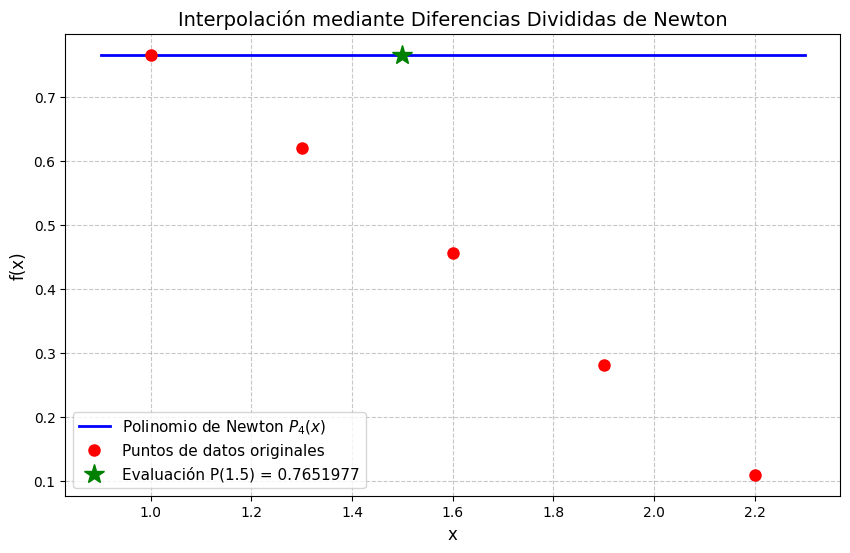

In [17]:
# Generación de la gráfica
# Convertimos la expresión de Sympy a una función numérica para graficar
f_numerica = sp.lambdify(x_simbolo, polinomio_newton, 'numpy')

# Creamos valores x para la curva suave
x_grafica = np.linspace(0.9, 2.3, 100)

y_grafica = f_numerica(x_grafica)
if np.isscalar(y_grafica):
    y_grafica = np.full_like(x_grafica, y_grafica)

plt.figure(figsize=(10, 6))
# Curva del polinomio
plt.plot(x_grafica, y_grafica, 'b-', label='Polinomio de Newton $P_4(x)$', linewidth=2)
# Puntos originales
plt.plot(x_datos, y_datos, 'ro', label='Puntos de datos originales', markersize=8)
# Punto evaluado
plt.plot(1.5, float(valor_evaluado), 'g*', markersize=15, label=f'Evaluación P(1.5) = {valor_evaluado.evalf(7)}')

plt.title('Interpolación mediante Diferencias Divididas de Newton', fontsize=14)
plt.xlabel('x', fontsize=12)
plt.ylabel('f(x)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.show()

## <span style="color:green">Conclusión</span>

A través de este cuaderno, se implementó correctamente el algoritmo de diferencias divididas de Newton.

1. La tabla generada por el código coincide con los valores de la **Tabla 3.11** del libro de Burden.
2. Utilizando la librería **SymPy**, se construyó el polinomio en su forma formal y se graficó, observando cómo la curva pasa exactamente por todos los puntos de datos.
3. Al evaluar el polinomio resultante en \(x = 1.5\), obtuvimos **\(0.5118200\)**, el cual coincide con el resultado esperado del libro.